Loading datasets...


/tmp/ipykernel_846/2385882392.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


Chart successfully saved as 'allrecipes_visual_insights.png'!


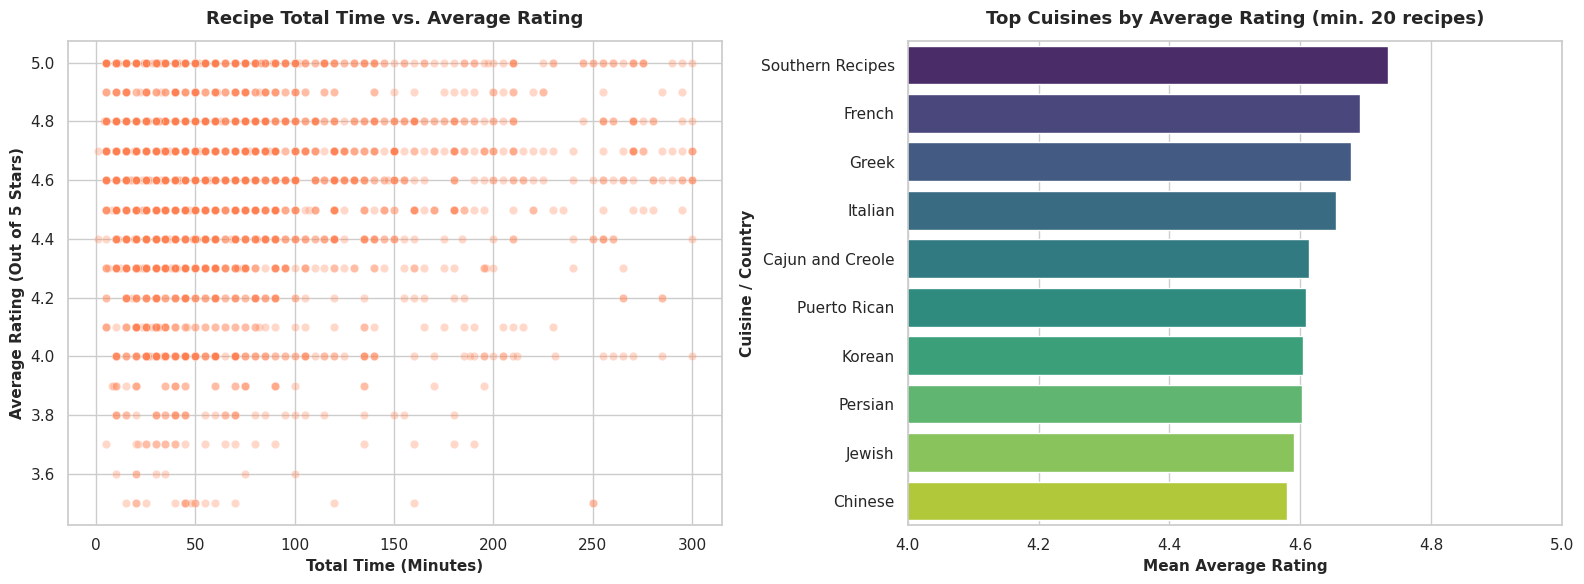

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Load Allrecipes and Cuisines datasets from TidyTuesday GitHub
url_recipes = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-09-16/all_recipes.csv"
url_cuisines = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-09-16/cuisines.csv"

print("Loading datasets...")
all_recipes = pd.read_csv(url_recipes)
cuisines = pd.read_csv(url_cuisines)

# 2. Set up the plotting canvas with 2 subplots
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- PLOT 1: Prep/Cook Time vs. Average Rating ---
# Filter out extreme outliers for cleaner visualization (Total time <= 300 mins, Rating >= 3.5)
filtered_recipes = all_recipes[
    (all_recipes["total_time"] > 0)
    & (all_recipes["total_time"] <= 300)
    & (all_recipes["avg_rating"] >= 3.5)
]

sns.scatterplot(
    data=filtered_recipes.sample(
        min(3000, len(filtered_recipes)), random_state=42
    ),
    x="total_time",
    y="avg_rating",
    alpha=0.3,
    color="coral",
    ax=axes[0],
)
axes[0].set_title(
    "Recipe Total Time vs. Average Rating", fontsize=13, fontweight="bold", pad=12
)
axes[0].set_xlabel("Total Time (Minutes)", fontsize=11, fontweight="bold")
axes[0].set_ylabel(
    "Average Rating (Out of 5 Stars)", fontsize=11, fontweight="bold"
)

# --- PLOT 2: Top Cuisines by Average Rating ---
# Aggregate by country/cuisine, filtering for categories with at least 20 recipes
cuisine_summary = (
    cuisines.groupby("country")
    .agg({"avg_rating": "mean", "total_ratings": "sum", "name": "count"})
    .reset_index()
)
top_cuisines = cuisine_summary[cuisine_summary["name"] >= 20].sort_values(
    by="avg_rating", ascending=False
)

sns.barplot(
    data=top_cuisines.head(10),
    x="avg_rating",
    y="country",
    palette="viridis",
    ax=axes[1],
)
axes[1].set_title(
    "Top Cuisines by Average Rating (min. 20 recipes)",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
axes[1].set_xlabel("Mean Average Rating", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Cuisine / Country", fontsize=11, fontweight="bold")
axes[1].set_xlim(
    4.0, 5.0
)  # Zoom in on the high rating cluster typical of Allrecipes

# Final Layout Adjustments
plt.tight_layout()
plt.savefig("allrecipes_visual_insights.png", dpi=300)
print("Chart successfully saved as 'allrecipes_visual_insights.png'!")
plt.show()